# Lab for Lesson 1 - Introduction to AI Methods for Embedded Systems (Using Keras)

## Importing Required Libraries

In [5]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import keras
from keras import layers
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import shutil
import random
import sys
import ctypes
import threading
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from pathlib import Path
import seaborn as sns
# from ansys.scadeone.core import ScadeOne
# from ansys.scadeone.core.svc.pywrapper.python_wrapper import PythonWrapper

## Utilities

In [7]:
keras.utils.set_random_seed(42)
print("Keras version:", keras.__version__)
print("TensorFlow version:", tf.__version__)
print(tf.config.list_physical_devices())


Keras version: 3.15.1
TensorFlow version: 2.21.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## Introducing a regression problem: Neural-Network Sensor Calibration

### Generating the Sensor Dataset

In [8]:
rng = np.random.default_rng(42)
n_samples = 2000
temperature_c = rng.uniform(
    low=-20.0,
    high=80.0,
    size=n_samples
)
ideal_voltage = (
    0.50
    + 0.012 * temperature_c
    + 0.00004 * temperature_c**2
)
measured_voltage = ideal_voltage + rng.normal(
    loc=0.0,
    scale=0.015,
    size=n_samples
)
# The parameter “-1” of the reshape method allows numpy to compute the dimension of that axis.
X = measured_voltage.reshape(-1, 1).astype("float32")
y = temperature_c.reshape(-1, 1).astype("float32")

In [13]:
print(measured_voltage)

[1.30514954 0.82310023 1.44577754 ... 0.66835843 1.43549441 0.92545414]


In [9]:
print(X)

[[1.3051496 ]
 [0.8231002 ]
 [1.4457775 ]
 ...
 [0.66835845]
 [1.4354944 ]
 [0.92545414]]


In [14]:
print(temperature_c)

[57.39560486 23.88784398 65.85979199 ... 13.50468775 64.56994006
 32.00719123]


In [10]:
print(y)

[[57.395603]
 [23.887844]
 [65.859795]
 ...
 [13.504687]
 [64.56994 ]
 [32.00719 ]]


### Visualize the generated dataset

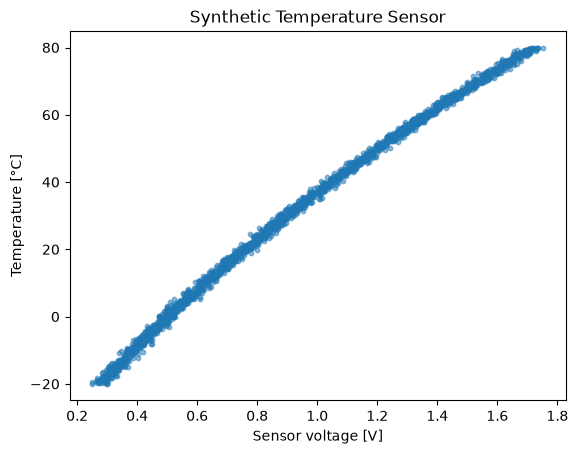

In [11]:
plt.scatter(
    measured_voltage,
    temperature_c,
    s=10,
    alpha=0.5
)
plt.xlabel("Sensor voltage [V]")
plt.ylabel("Temperature [°C]")
plt.title("Synthetic Temperature Sensor")
plt.show()

### Splitting the Dataset

In [ ]:
# 70% of the dataset is used for training, the remaining 30% is split equally between validation and test sets.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 1400
Validation samples: 300
Test samples: 300


### Input Normalization

In [15]:
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)
print("Mean:", normalizer.mean.numpy())
print("Variance:", normalizer.variance.numpy())

Mean: [[0.9372412]]
Variance: [[0.17434666]]
